# 05 · When I sleep, not just how long

Bedtimes are measured from the start of the night's date, so 00:30 is 24.5 h rather than 0.5 —
otherwise a Friday that runs past midnight averages out to midday.

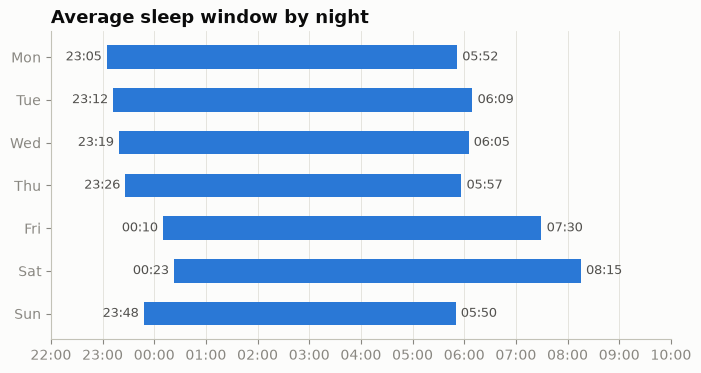

In [1]:
from sleep_patterns.clean import nightly
from sleep_patterns.io import load_sleep
from sleep_patterns.metrics import bedtime_spread, social_jetlag
from sleep_patterns import plots

nights = nightly(load_sleep())
plots.sleep_window(nights);

In [2]:
jetlag = social_jetlag(nights)
print(f"social jetlag: {jetlag:.2f} h ({jetlag * 60:.0f} min)")

social jetlag: 1.41 h (85 min)


Weekends shift my whole sleep window about an hour and a half later. Sunday night then has
to snap back to a Monday alarm, which is most of why Sunday is the shortest night (notebook 02).

In [3]:
bedtime_spread(nights).round(1).to_frame("bedtime std (min)")

,bedtime std (min)
weekday,
Monday,31.9
Tuesday,25.9
Wednesday,32.2
Thursday,25.8
Friday,31.2
Saturday,26.3
Sunday,33.0


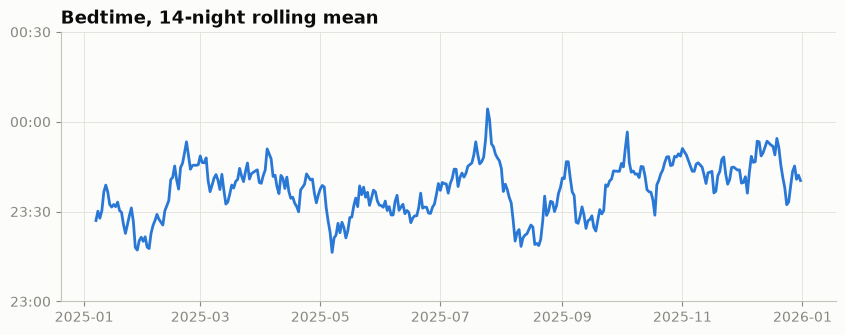

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(nights["night"], nights["bedtime"].rolling(14, min_periods=7).mean(), color=plots.BLUE)
ax.set_yticks([23, 23.5, 24, 24.5], ["23:00", "23:30", "00:00", "00:30"])
ax.set_title("Bedtime, 14-night rolling mean");